In [1]:
import numpy as np
import matplotlib.pyplot as plt

Zadanie 1

C:\Users\zuzan\AppData\Local\Temp\ipykernel_21608\1973434939.py:5: RuntimeWarning: divide by zero encountered in divide
  y2 = 1/x
C:\Users\zuzan\AppData\Local\Temp\ipykernel_21608\1973434939.py:7: RuntimeWarning: divide by zero encountered in divide
  y4 = 15/x**8


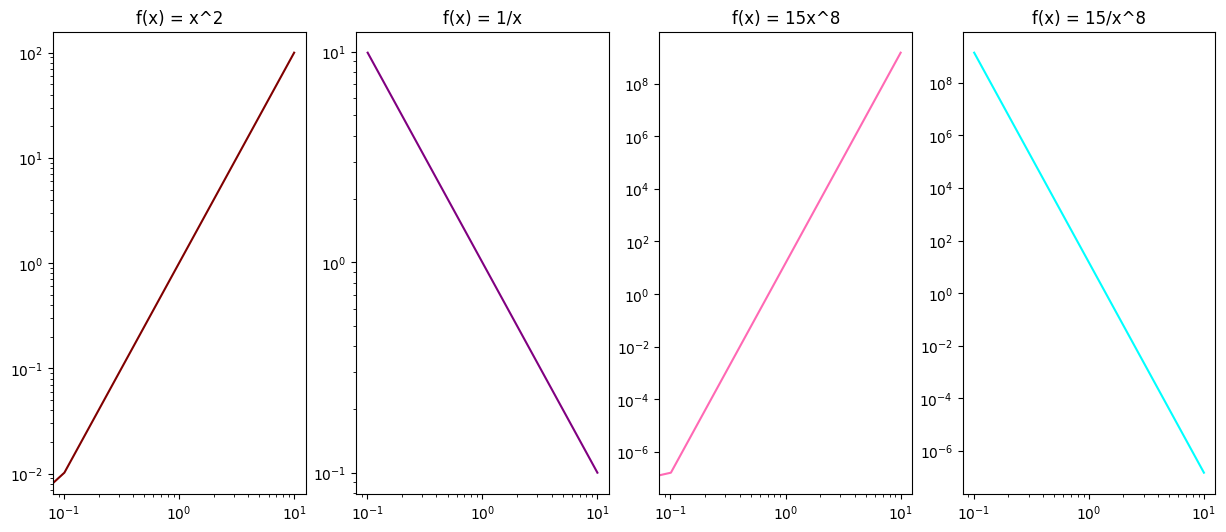

In [2]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4,figsize=(15, 6))

x = np.linspace(0, 10, 100)
y1 = x**2
y2 = 1/x
y3 = 15*x**8
y4 = 15/x**8

def draw_plot(ax, x, y, title, color):
    ax.plot(x, y, label=f'y = {y[0]}', c=color)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(f'{title}')
    

draw_plot(ax1, x, y1, 'f(x) = x^2', 'maroon')
draw_plot(ax2, x, y2, 'f(x) = 1/x', 'purple')
draw_plot(ax3, x, y3, 'f(x) = 15x^8', 'hotpink')
draw_plot(ax4, x, y4, 'f(x) = 15/x^8', 'cyan')

Zadanie 2

In [3]:
from word_count import print_top_words, word_counts, draw_freq_words_plot

top_30 = print_top_words('gutenberg.txt', 30)
words = word_counts('gutenberg.txt')

word_num = np.sum(list(words.values()))

def word_freq(word):
    return words.get(word) / word_num

print("#"*10)
print(f'{word_freq("the"):.4f}')

# for word in words:
#     print(f'{word}: {word_freq(word)[0]:.4f}')


Top 30 słów w pliku gutenberg.txt:
the                  : 133211
and                  : 94787
of                   : 71173
to                   : 47591
a                    : 33573
in                   : 33391
i                    : 28593
that                 : 28241
he                   : 25408
it                   : 21537
his                  : 21375
for                  : 19396
was                  : 18647
with                 : 17560
not                  : 17281
is                   : 16343
be                   : 16056
you                  : 15878
as                   : 14463
but                  : 13558
all                  : 13557
they                 : 12983
him                  : 12928
shall                : 11676
her                  : 11446
my                   : 10462
had                  : 10305
them                 : 10197
have                 : 10100
said                 : 9396
##########
0.0624


In [ ]:
def draw_freq_words_plot(input_file, num=30):
    fig, ax = plt.subplots(figsize=(10, 6))
    lst = list_words_in_file(input_file)
    words, counts = np.unique(lst, return_counts=True)
    idx = np.argsort(counts)[:-(num+1):-1]
    plt.title(f"Top {num} słów w pliku {input_file}:")
    xs, ys = [], []
    for i in idx:
        xs.append(words[i])
        ys.append(counts[i]/np.sum(counts))
    ax.plot(xs, ys, color='maroon', marker='o', linewidth=2)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('N (skala logarytmiczna)')
    ax.set_ylabel('Częstotliwość (skala logarytmiczna)')
    ax.set_title("Częstotliwość n-tego słowa")
    ax.grid(True, which='both')

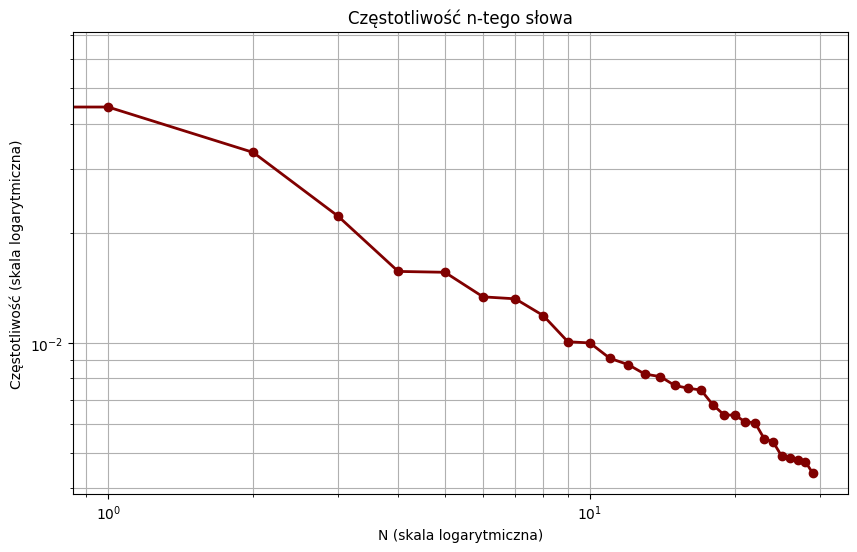

In [4]:
draw_freq_words_plot('gutenberg.txt', 30)

Zadanie 3

In [22]:
from word_count import letter_counts

languages = {'english': ('e', 't', 'a'),
                 'spanish': ('e', 'a', 'o'),
                 'polish': ('a', 'i', 'e')}

def guess_language(input_file, languages):
    letter_count = letter_counts(input_file).most_common(3)
    for language, letters in languages.items():
        threes = (letter_count[0][0], letter_count[1][0], letter_count[2][0])
        if threes == letters:
            return language
    return "unknown"

assert guess_language('english.txt', languages) == 'english'
assert guess_language('spanish.txt', languages) == 'spanish'
assert guess_language('polish.txt', languages) == 'polish'
assert guess_language('german.txt', languages) == 'unknown'



Zadanie 4

In [32]:
def adjacent_rooms(input_file):
    d = {}
    with open(input_file, encoding='utf8') as f:
        for line in f:
            rooms = line.strip().split(':')
            d[rooms[0]] = rooms[1].split(',')
    return d

def treasure_rooms(input_file):
    d = {}
    with open(input_file, encoding='utf8') as f:
        for line in f:
            rooms = line.strip().split(',')
            d[rooms[0]] = int(rooms[1])
    return d

rooms = adjacent_rooms('board.txt')
treasure = treasure_rooms('treasures.csv')

In [35]:
def num_close_treasures(chamber):
    num = 0
    adjacent_chambers = rooms[chamber]
    for chambs in adjacent_chambers:
        num += treasure[chambs]
    return num

num_close_treasures("Spichlerz")

2

In [42]:
def get_nearby_treasures(chamber):
    lst = []
    adjacent_chambers = rooms[chamber]
    for chambs in adjacent_chambers:
        if treasure[chambs] == 1:
            lst.append(chambs)
    if len(lst) == 0:
        return "Brak skarbu w pobliżu"
    return lst

get_nearby_treasures("Kryjówka szczurów")

'Brak skarbu w pobliżu'

In [47]:
def competing_chambers(chamber1, chamber2):
    chamb1_neighboors = get_nearby_treasures(chamber1)
    chamb2_neighboors = get_nearby_treasures(chamber2)
    neighbours = list(set(chamb1_neighboors) & set(chamb2_neighboors))
    for neighbour in neighbours:
        if treasure[neighbour] == 1:
            return True
    return False

print(competing_chambers('Komnata maga', 'Studium'))
print(competing_chambers('Stajnia', 'Dziedziniec'))


False
True
